# Oracle vs Real Embeddings

Сравниваем пространство сгенерированных моделью (oracle) эмбеддингов с реальными эмбеддингами в 256d.

1. **Загрузка** — модель, тестовые данные, генерация oracle
2. **Глобальные статистики** — нормы, попарные косинусы, per-component std
3. **UMAP** — где oracle приземляются относительно реальных товаров
4. **Близость к таргету** — насколько oracle близок к правильному товару
5. **Покрытие пространства** — нет ли коллапса к центру

In [3]:
import sys
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm
import torch

sys.path.append('../src')
from whitening import apply_whitening, load_whitening
from models.flow_matcher import FlowMatcher
from data import build_dataloaders

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

DATA_DIR      = Path('../data/ATG')
EMB_PATH      = DATA_DIR / '3large_emb.pickle'
WH_CACHE_PATH = Path('../data/processed/whitening_cache.npz')
CKPT_DIR      = Path('../checkpoints/baseline_2')
PADDING_IDX   = 11924
N_COMPONENTS  = 256

# Inference params
NUM_STEPS = 100
W_CFG     = 0.0
BATCH_SIZE = 256

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

ckpt_path = CKPT_DIR / 'best.pt'
if not ckpt_path.exists():
    ckpt_path = CKPT_DIR / 'latest.pt'
print(f'Checkpoint: {ckpt_path}  exists={ckpt_path.exists()}')

Device: cuda
Checkpoint: ..\checkpoints\baseline_2\best.pt  exists=True


## 1. Загрузка модели и генерация oracle эмбеддингов

In [4]:
# Загружаем сырые эмбеддинги для инициализации модели
with open(EMB_PATH, 'rb') as f:
    emb_raw = pickle.load(f).astype(np.float32)
print(f'Raw embeddings: {emb_raw.shape}')

# Загружаем модель
ckpt = torch.load(ckpt_path, map_location=device)
print(f'Checkpoint: epoch={ckpt.get("epoch")}, metrics={ckpt.get("metrics")}')

model = FlowMatcher(
    item_embeddings_raw=emb_raw,
    padding_idx=PADDING_IDX,
    n_components=N_COMPONENTS,
    whitening_cache_path=WH_CACHE_PATH,
    # Encoder
    d_hidden=512, d_cond=512,
    encoder_layers=2, encoder_heads=8, encoder_d_ff=2048,
    # Denoiser  
    denoiser_d_block=512, denoiser_d_ff=1024,
    denoiser_n_blocks=6, denoiser_time_emb_dim=128,
).to(device)

model.load_state_dict(ckpt['model_state'])

# Используем EMA-веса если есть
if 'ema_shadow' in ckpt:
    for name, param in model.named_parameters():
        if name in ckpt['ema_shadow']:
            param.data.copy_(ckpt['ema_shadow'][name].to(device))
    print('EMA weights loaded')

model.eval()
print(f'Model loaded. Params: {model.param_summary()}')

Raw embeddings: (11924, 3072)
Checkpoint: epoch=95, metrics={'HR@10': 0.015971148386597633, 'NDCG@10': 0.014430739916861057, 'HR@20': 0.01803194172680378, 'NDCG@20': 0.014937503263354301}
Loading whitening from cache: ..\data\processed\whitening_cache.npz
EMA weights loaded
Model loaded. Params: {'encoder_trainable': 6704128, 'encoder_frozen': 3052800, 'denoiser_trainable': 9788160, 'phi': 512, 'total_trainable': 16492800, 'total_frozen': 3052800}


In [5]:
# Загружаем тестовые данные
loaders = build_dataloaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    num_workers=0,
    splits=('test',),
)
test_loader = loaders['test']
print(f'Test set: {len(test_loader.dataset):,} sequences')

Test set: 1,942 sequences


In [6]:
# Генерируем oracle embeddings для всего тестового сета
oracle_list = []
target_list = []

torch.manual_seed(42)
with torch.no_grad():
    for batch in tqdm(test_loader, desc='Generating oracle embeddings'):
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target']

        oracle = model.sample(history, mask, num_steps=NUM_STEPS, w_cfg=W_CFG)

        # Реальные эмбеддинги целевых товаров в 256d (из frozen embedding table)
        target_emb = model.encoder.item_embedding(target.to(device))

        oracle_list.append(oracle.cpu().numpy())
        target_list.append(target_emb.cpu().numpy())

oracle_emb = np.vstack(oracle_list)  # (N_test, 256)
target_emb = np.vstack(target_list)  # (N_test, 256)

print(f'Oracle embeddings: {oracle_emb.shape}')
print(f'Target embeddings: {target_emb.shape}')

# Также возьмём все реальные item embeddings (весь каталог)
all_item_emb = model.encoder.item_embedding.weight[:model.n_items].cpu().numpy()  # (N_items, 256)
print(f'All item embeddings: {all_item_emb.shape}')

Generating oracle embeddings:   0%|          | 0/8 [00:00<?, ?it/s]

Oracle embeddings: (1942, 256)
Target embeddings: (1942, 256)
All item embeddings: (11924, 256)


## 2. Глобальные статистики

In [7]:
def describe(name, emb):
    norms  = np.linalg.norm(emb, axis=1)
    print(f'{name}:')
    print(f'  shape:          {emb.shape}')
    print(f'  global mean:    {emb.mean():.4f}')
    print(f'  global std:     {emb.std():.4f}')
    print(f'  norm mean/std:  {norms.mean():.3f} / {norms.std():.3f}')
    print(f'  per-dim std:    min={emb.std(0).min():.3f}, '
          f'max={emb.std(0).max():.3f}, mean={emb.std(0).mean():.3f}')

describe('All real items (256d)', all_item_emb)
print()
describe('Target items (test)', target_emb)
print()
describe('Oracle (generated)', oracle_emb)

All real items (256d):
  shape:          (11924, 256)
  global mean:    0.0000
  global std:     1.0000
  norm mean/std:  15.984 / 0.712
  per-dim std:    min=0.472, max=3.378, mean=0.881

Target items (test):
  shape:          (1942, 256)
  global mean:    -0.0027
  global std:     1.0018
  norm mean/std:  16.013 / 0.710
  per-dim std:    min=0.463, max=3.547, mean=0.879

Oracle (generated):
  shape:          (1942, 256)
  global mean:    -0.0009
  global std:     0.8234
  norm mean/std:  13.046 / 1.829
  per-dim std:    min=0.347, max=3.479, mean=0.676


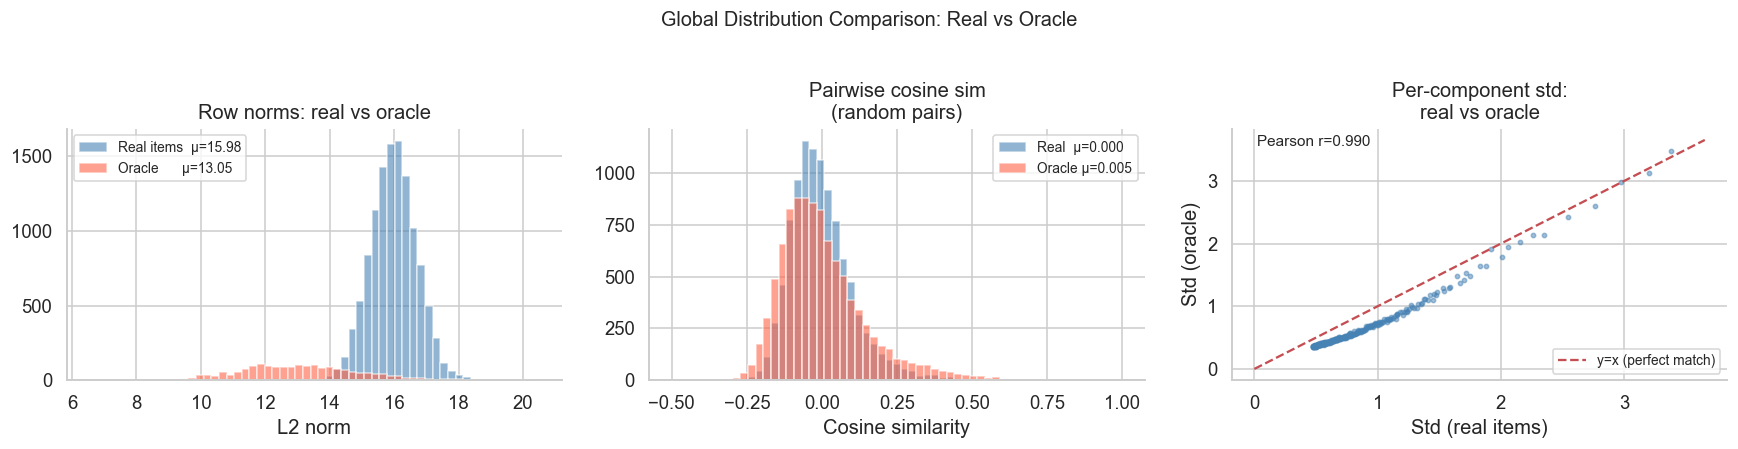

In [8]:
rng = np.random.default_rng(42)

norms_real   = np.linalg.norm(all_item_emb, axis=1)
norms_target = np.linalg.norm(target_emb,   axis=1)
norms_oracle = np.linalg.norm(oracle_emb,   axis=1)

def cosine_sample(emb, n=10000):
    idx = rng.choice(len(emb), size=min(3000, len(emb)), replace=False)
    s = emb[idx].astype(np.float64)
    s = s / (np.linalg.norm(s, axis=1, keepdims=True) + 1e-10)
    i = rng.integers(0, len(s), n); j = rng.integers(0, len(s), n)
    m = i != j
    return (s[i[m]] * s[j[m]]).sum(axis=1)

cos_real   = cosine_sample(all_item_emb)
cos_oracle = cosine_sample(oracle_emb)

std_real   = all_item_emb.std(axis=0)  # (256,)
std_oracle = oracle_emb.std(axis=0)    # (256,)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- Нормы ---
ax = axes[0]
bins = np.linspace(min(norms_real.min(), norms_oracle.min()) - 0.5,
                   max(norms_real.max(), norms_oracle.max()) + 0.5, 60)
ax.hist(norms_real,   bins=bins, alpha=0.6, color='steelblue', edgecolor='white',
        label=f'Real items  μ={norms_real.mean():.2f}')
ax.hist(norms_oracle, bins=bins, alpha=0.6, color='tomato', edgecolor='white',
        label=f'Oracle      μ={norms_oracle.mean():.2f}')
ax.set_xlabel('L2 norm')
ax.set_title('Row norms: real vs oracle')
ax.legend(fontsize=9)

# --- Косинусные сходства ---
ax = axes[1]
bins2 = np.linspace(-0.5, 1.0, 60)
ax.hist(cos_real,   bins=bins2, alpha=0.6, color='steelblue', edgecolor='white',
        label=f'Real  μ={cos_real.mean():.3f}')
ax.hist(cos_oracle, bins=bins2, alpha=0.6, color='tomato', edgecolor='white',
        label=f'Oracle μ={cos_oracle.mean():.3f}')
ax.set_xlabel('Cosine similarity')
ax.set_title('Pairwise cosine sim\n(random pairs)')
ax.legend(fontsize=9)

# --- Per-dim std: real vs oracle ---
ax = axes[2]
ax.scatter(std_real, std_oracle, s=8, alpha=0.5, color='steelblue')
lim = max(std_real.max(), std_oracle.max()) * 1.05
ax.plot([0, lim], [0, lim], 'r--', lw=1.5, label='y=x (perfect match)')
ax.set_xlabel('Std (real items)')
ax.set_ylabel('Std (oracle)')
ax.set_title('Per-component std:\nreal vs oracle')
ax.legend(fontsize=9)
r = np.corrcoef(std_real, std_oracle)[0, 1]
ax.text(0.05, 0.93, f'Pearson r={r:.3f}', transform=ax.transAxes, fontsize=10)

plt.suptitle('Global Distribution Comparison: Real vs Oracle', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 3. UMAP: где oracle приземляются

In [9]:
try:
    import umap
    HAS_UMAP = True
except ImportError:
    print('pip install umap-learn')
    HAS_UMAP = False

Fitting UMAP on real embeddings...


c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Transforming oracle embeddings...
Done.


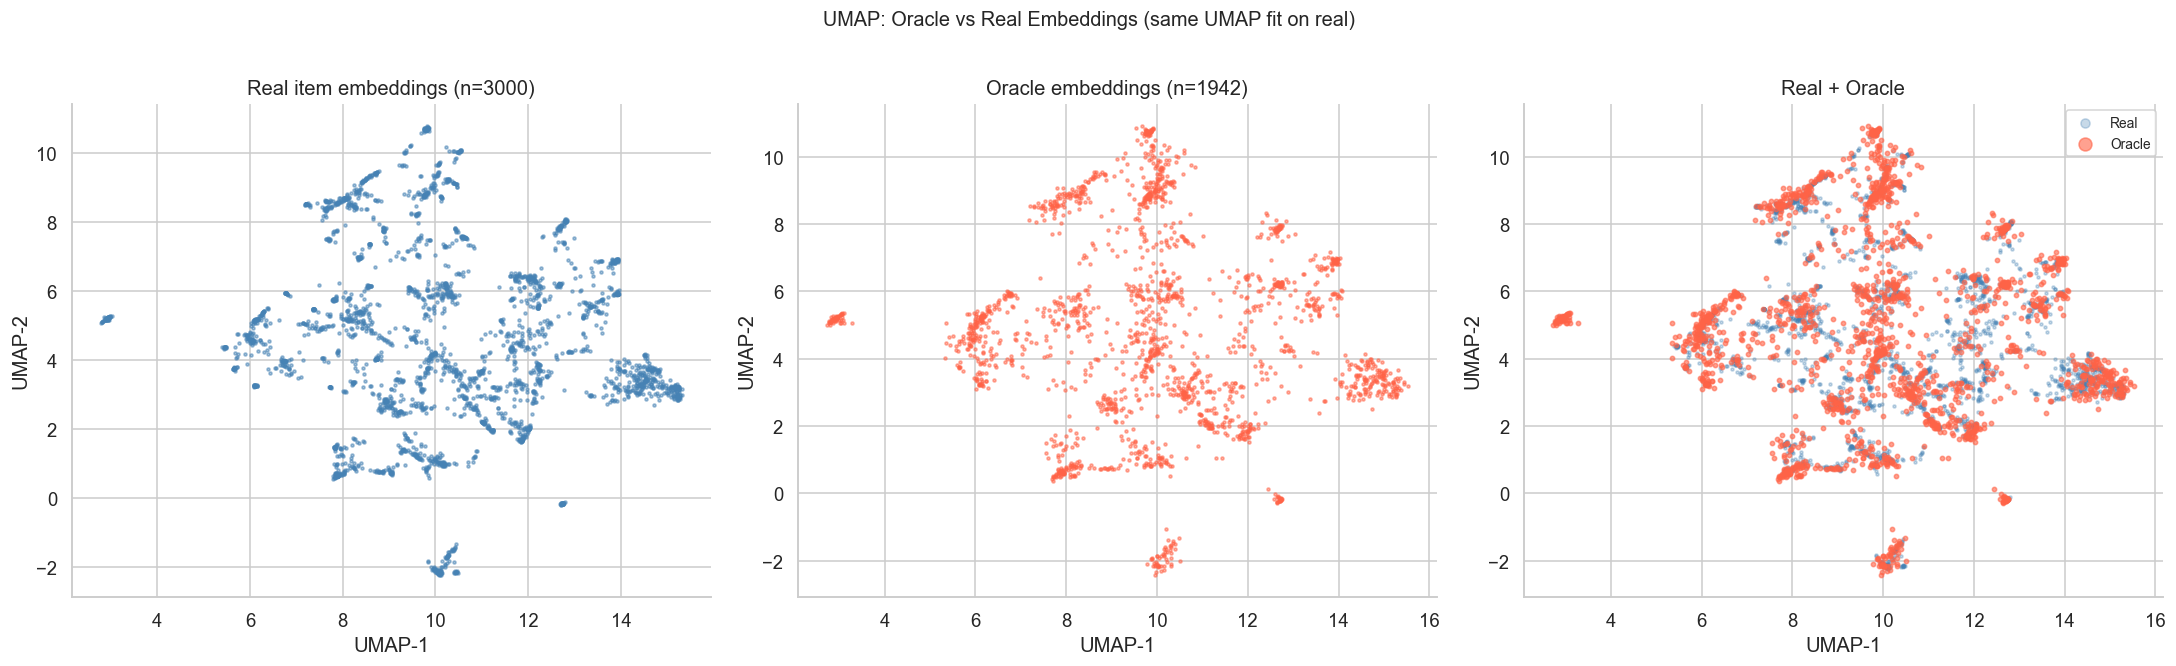

In [10]:
if HAS_UMAP:
    N_REAL_SAMPLE   = 3000
    N_ORACLE_SAMPLE = min(len(oracle_emb), 2000)

    real_idx   = rng.choice(len(all_item_emb), size=N_REAL_SAMPLE, replace=False)
    oracle_idx = rng.choice(len(oracle_emb),   size=N_ORACLE_SAMPLE, replace=False)

    # Обучаем UMAP на реальных эмбеддингах, трансформируем oracle тем же reducer
    # Это ключевой момент: oracle попадают в то же UMAP-пространство
    print('Fitting UMAP on real embeddings...')
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=30,
        min_dist=0.05,
        metric='cosine',
        random_state=42,
        verbose=False,
    )
    real_2d   = reducer.fit_transform(all_item_emb[real_idx])
    print('Transforming oracle embeddings...')
    oracle_2d = reducer.transform(oracle_emb[oracle_idx])
    print('Done.')

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # --- Только реальные ---
    ax = axes[0]
    ax.scatter(real_2d[:, 0], real_2d[:, 1],
               s=4, alpha=0.5, color='steelblue', rasterized=True)
    ax.set_title(f'Real item embeddings (n={N_REAL_SAMPLE})')
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')

    # --- Только oracle ---
    ax = axes[1]
    ax.scatter(oracle_2d[:, 0], oracle_2d[:, 1],
               s=4, alpha=0.5, color='tomato', rasterized=True)
    ax.set_title(f'Oracle embeddings (n={N_ORACLE_SAMPLE})')
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')

    # --- Оба вместе ---
    ax = axes[2]
    ax.scatter(real_2d[:, 0],   real_2d[:, 1],
               s=4, alpha=0.3, color='steelblue', label='Real', rasterized=True)
    ax.scatter(oracle_2d[:, 0], oracle_2d[:, 1],
               s=8, alpha=0.6, color='tomato',    label='Oracle', rasterized=True)
    ax.set_title('Real + Oracle')
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
    ax.legend(fontsize=9, markerscale=3)

    plt.suptitle('UMAP: Oracle vs Real Embeddings (same UMAP fit on real)', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print('Skipping UMAP.')

## 4. Близость oracle к целевому товару

Cosine(oracle, target):  mean=0.0171, median=-0.0142, std=0.1580
Cosine(oracle, random):  mean=0.0059, median=-0.0157, std=0.1254
L2(oracle, target):      mean=20.4203, median=20.6162


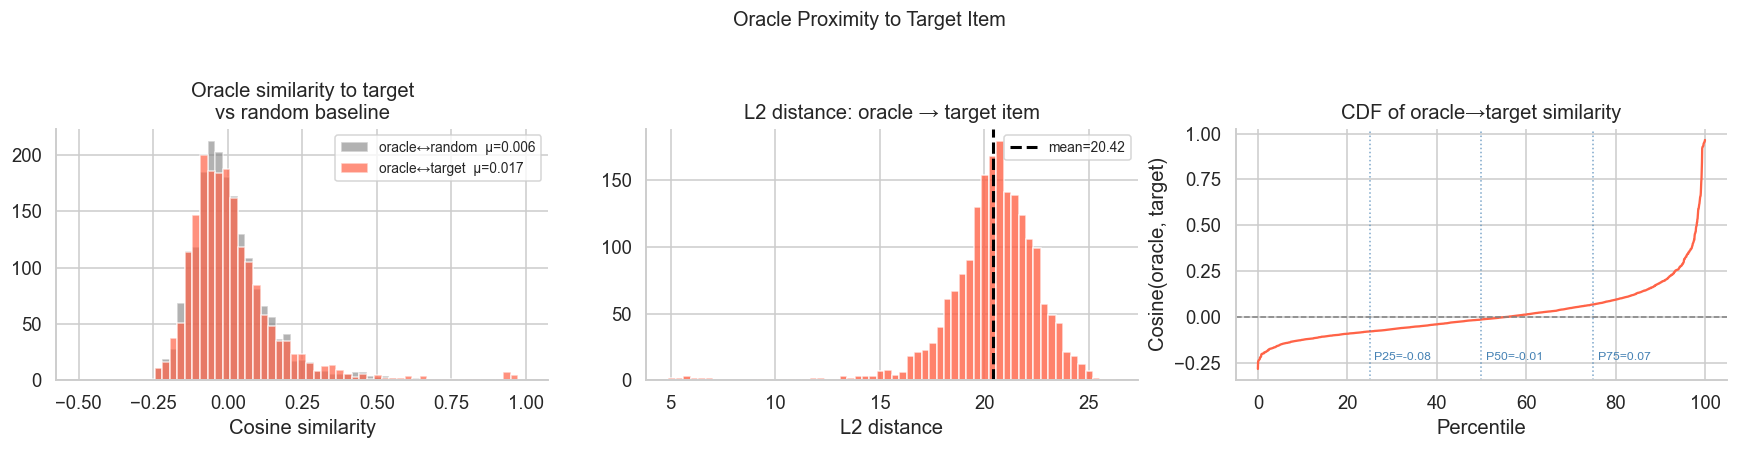

In [11]:
# Косинусное сходство oracle с target (правильным товаром)
def cosine_sim_rows(a, b):
    a_n = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-10)
    b_n = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-10)
    return (a_n * b_n).sum(axis=1)

cos_oracle_target = cosine_sim_rows(oracle_emb, target_emb)  # (N_test,)

# Baseline: сходство случайных пар (oracle, random_item)
rand_idx = rng.choice(len(all_item_emb), size=len(oracle_emb), replace=True)
cos_oracle_random = cosine_sim_rows(oracle_emb, all_item_emb[rand_idx])

# L2 расстояние oracle до target
l2_oracle_target = np.linalg.norm(oracle_emb - target_emb, axis=1)

print(f'Cosine(oracle, target):  mean={cos_oracle_target.mean():.4f}, '
      f'median={np.median(cos_oracle_target):.4f}, std={cos_oracle_target.std():.4f}')
print(f'Cosine(oracle, random):  mean={cos_oracle_random.mean():.4f}, '
      f'median={np.median(cos_oracle_random):.4f}, std={cos_oracle_random.std():.4f}')
print(f'L2(oracle, target):      mean={l2_oracle_target.mean():.4f}, '
      f'median={np.median(l2_oracle_target):.4f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- Косинусное сходство oracle↔target vs oracle↔random ---
ax = axes[0]
bins = np.linspace(-0.5, 1.0, 60)
ax.hist(cos_oracle_random, bins=bins, alpha=0.6, color='gray', edgecolor='white',
        label=f'oracle↔random  μ={cos_oracle_random.mean():.3f}')
ax.hist(cos_oracle_target, bins=bins, alpha=0.7, color='tomato', edgecolor='white',
        label=f'oracle↔target  μ={cos_oracle_target.mean():.3f}')
ax.set_xlabel('Cosine similarity')
ax.set_title('Oracle similarity to target\nvs random baseline')
ax.legend(fontsize=9)

# --- L2 расстояние oracle до target ---
ax = axes[1]
ax.hist(l2_oracle_target, bins=60, color='tomato', alpha=0.8, edgecolor='white')
ax.axvline(l2_oracle_target.mean(), color='black', ls='--', lw=2,
           label=f'mean={l2_oracle_target.mean():.2f}')
ax.set_xlabel('L2 distance')
ax.set_title('L2 distance: oracle → target item')
ax.legend(fontsize=9)

# --- Scatter: cos(oracle,target) по квантилям (percentile plot) ---
ax = axes[2]
sorted_cos = np.sort(cos_oracle_target)
pct = np.linspace(0, 100, len(sorted_cos))
ax.plot(pct, sorted_cos, color='tomato', lw=1.5)
ax.axhline(0, color='gray', ls='--', lw=1)
ax.set_xlabel('Percentile')
ax.set_ylabel('Cosine(oracle, target)')
ax.set_title('CDF of oracle→target similarity')
# Отмечаем key percentiles
for p in [25, 50, 75]:
    v = np.percentile(cos_oracle_target, p)
    ax.axvline(p, color='steelblue', ls=':', lw=1, alpha=0.7)
    ax.text(p + 1, sorted_cos[0] + 0.05, f'P{p}={v:.2f}', fontsize=8, color='steelblue')

plt.suptitle('Oracle Proximity to Target Item', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 5. Ранг таргета в списке рекомендаций

In [12]:
# Для подвыборки считаем rank таргета среди всех N_items
# Это дорого O(N_test * N_items) — берём подвыборку
N_RANK_SAMPLE = min(500, len(oracle_emb))
rank_idx = rng.choice(len(oracle_emb), size=N_RANK_SAMPLE, replace=False)

oracle_sub = torch.tensor(oracle_emb[rank_idx], dtype=torch.float32).to(device)

# Embedding table без padding
item_emb_t = model.encoder.item_embedding.weight[:model.n_items]  # (N_items, 256)

# Считаем ранги батчами
print(f'Computing ranks for {N_RANK_SAMPLE} queries against {model.n_items:,} items...')
ranks = []
RANK_BATCH = 64
with torch.no_grad():
    for batch_idx in tqdm(range(len(rank_idx))):
        global_idx = rank_idx[batch_idx]
        q = oracle_emb[global_idx]   # (256,)
        # Получаем реальный индекс таргета из тестового датасета
        # Считаем score со всеми items
        q_t = torch.tensor(q, dtype=torch.float32, device=device)
        scores = (item_emb_t @ q_t).cpu().numpy()  # (N_items,)

        # Индекс таргета в embedding table соответствует его id напрямую
        # Находим его через target_emb[global_idx]
        t_emb = target_emb[global_idx]  # (256,)
        # Ранг: сколько items имеют score >= score таргета
        # Таргет — item с эмбеддингом target_emb[global_idx]
        # Ищем его через argmax cosine с target_emb
        target_scores = (item_emb_t.cpu().numpy() * t_emb[None, :]).sum(axis=1)
        target_item_id = int(target_scores.argmax())  # восстанавливаем id таргета
        target_score = scores[target_item_id]
        rank = int((scores > target_score).sum()) + 1  # 1-indexed
        ranks.append(rank)

ranks = np.array(ranks)

print(f'\nRank statistics (lower = better):')
print(f'  Median rank:  {np.median(ranks):.0f}')
print(f'  Mean rank:    {ranks.mean():.1f}')
print(f'  HR@1:   {(ranks <= 1).mean():.4f}')
print(f'  HR@5:   {(ranks <= 5).mean():.4f}')
print(f'  HR@10:  {(ranks <= 10).mean():.4f}')
print(f'  HR@20:  {(ranks <= 20).mean():.4f}')
print(f'  HR@50:  {(ranks <= 50).mean():.4f}')
print(f'  MRR:    {(1.0 / ranks).mean():.4f}')

Computing ranks for 500 queries against 11,924 items...


  0%|          | 0/500 [00:00<?, ?it/s]


Rank statistics (lower = better):
  Median rank:  5464
  Mean rank:    5482.8
  HR@1:   0.0120
  HR@5:   0.0120
  HR@10:  0.0140
  HR@20:  0.0160
  HR@50:  0.0220
  MRR:    0.0131


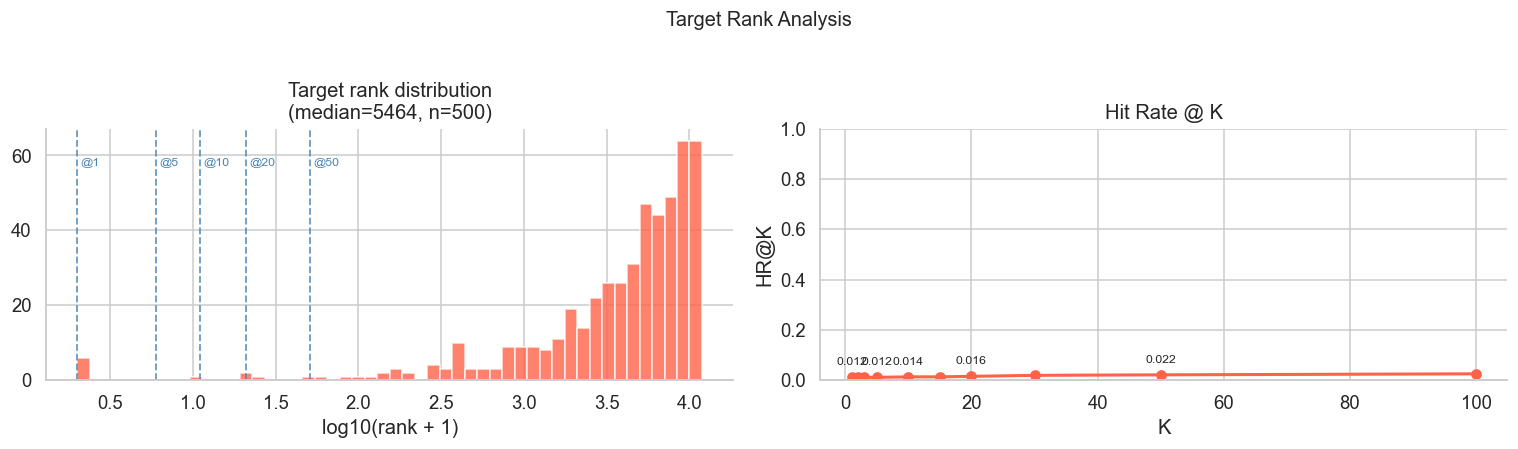

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# --- Распределение рангов (log scale) ---
ax = axes[0]
ax.hist(np.log10(ranks + 1), bins=50, color='tomato', alpha=0.8, edgecolor='white')
for k in [1, 5, 10, 20, 50]:
    ax.axvline(np.log10(k + 1), color='steelblue', ls='--', lw=1.2, alpha=0.8)
    ax.text(np.log10(k + 1) + 0.02, ax.get_ylim()[1] * 0.85,
            f'@{k}', fontsize=8, color='steelblue')
ax.set_xlabel('log10(rank + 1)')
ax.set_title(f'Target rank distribution\n(median={np.median(ranks):.0f}, n={N_RANK_SAMPLE})')

# --- HR@K кривая ---
ax = axes[1]
k_range = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
hr_values = [(ranks <= k).mean() for k in k_range]
ax.plot(k_range, hr_values, 'o-', color='tomato', lw=2, ms=6)
for k, hr in zip(k_range, hr_values):
    if k in [1, 5, 10, 20, 50]:
        ax.annotate(f'{hr:.3f}', (k, hr), textcoords='offset points',
                    xytext=(0, 8), fontsize=8, ha='center')
ax.set_xlabel('K')
ax.set_ylabel('HR@K')
ax.set_title('Hit Rate @ K')
ax.set_ylim(0, 1)

plt.suptitle('Target Rank Analysis', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 6. Покрытие пространства — нет ли mode collapse

Pairwise L2 (real):   mean=22.734, std=1.448
Pairwise L2 (oracle): mean=18.428, std=2.317

Distance from origin:
  Real:   mean norm=15.984
  Oracle: mean norm=13.046


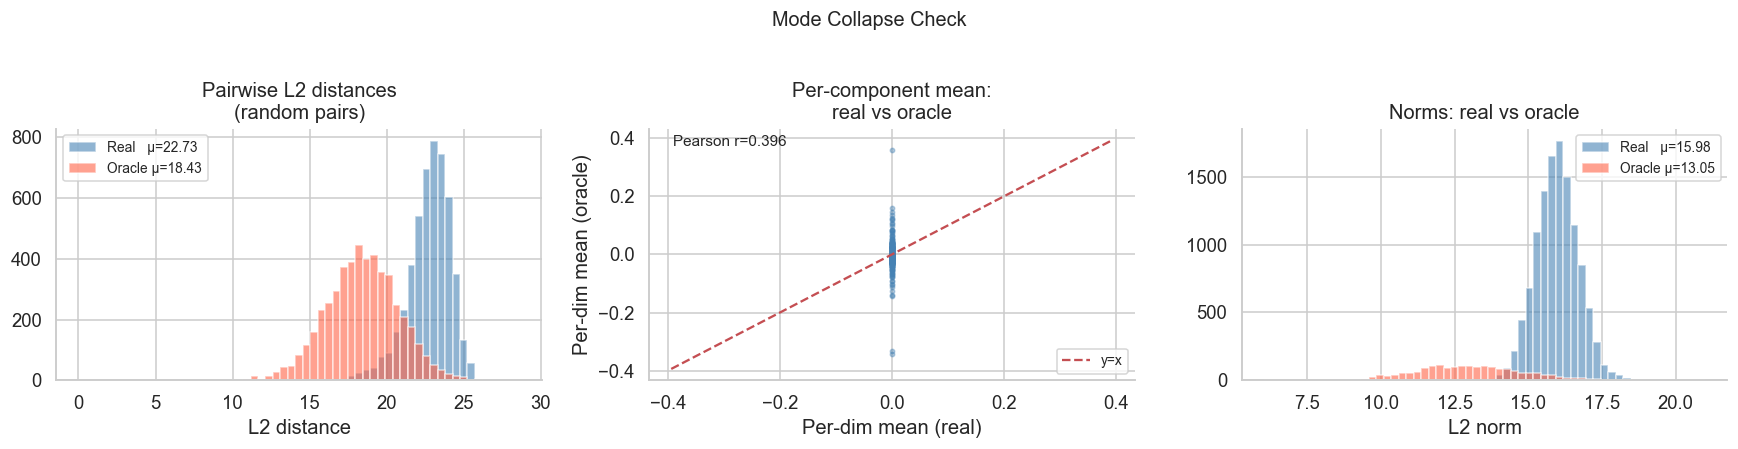

In [14]:
# Mode collapse: если oracle все близки к нулю или к одному центру
# Проверяем через:
# 1. Попарные расстояния между oracle (должны быть схожи с реальными)
# 2. Расстояние от oracle до центра (нуля)

# Выборка попарных L2 расстояний
def pairwise_l2_sample(emb, n=5000):
    idx = rng.choice(len(emb), size=min(500, len(emb)), replace=False)
    s = emb[idx].astype(np.float64)
    i = rng.integers(0, len(s), n); j = rng.integers(0, len(s), n)
    m = i != j
    return np.linalg.norm(s[i[m]] - s[j[m]], axis=1)

l2_real   = pairwise_l2_sample(all_item_emb)
l2_oracle = pairwise_l2_sample(oracle_emb)

print(f'Pairwise L2 (real):   mean={l2_real.mean():.3f}, std={l2_real.std():.3f}')
print(f'Pairwise L2 (oracle): mean={l2_oracle.mean():.3f}, std={l2_oracle.std():.3f}')
print(f'\nDistance from origin:')
print(f'  Real:   mean norm={norms_real.mean():.3f}')
print(f'  Oracle: mean norm={norms_oracle.mean():.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- Попарные L2 ---
ax = axes[0]
bins = np.linspace(0, max(l2_real.max(), l2_oracle.max()) + 1, 60)
ax.hist(l2_real,   bins=bins, alpha=0.6, color='steelblue', edgecolor='white',
        label=f'Real   μ={l2_real.mean():.2f}')
ax.hist(l2_oracle, bins=bins, alpha=0.6, color='tomato', edgecolor='white',
        label=f'Oracle μ={l2_oracle.mean():.2f}')
ax.set_xlabel('L2 distance')
ax.set_title('Pairwise L2 distances\n(random pairs)')
ax.legend(fontsize=9)

# --- Per-component mean: real vs oracle ---
ax = axes[1]
mean_real   = all_item_emb.mean(axis=0)
mean_oracle = oracle_emb.mean(axis=0)
ax.scatter(mean_real, mean_oracle, s=8, alpha=0.4, color='steelblue')
lim = max(np.abs(mean_real).max(), np.abs(mean_oracle).max()) * 1.1
ax.plot([-lim, lim], [-lim, lim], 'r--', lw=1.5, label='y=x')
ax.set_xlabel('Per-dim mean (real)')
ax.set_ylabel('Per-dim mean (oracle)')
ax.set_title('Per-component mean:\nreal vs oracle')
ax.legend(fontsize=9)
r_mean = np.corrcoef(mean_real, mean_oracle)[0, 1]
ax.text(0.05, 0.93, f'Pearson r={r_mean:.3f}', transform=ax.transAxes, fontsize=10)

# --- Нормы oracle vs norms real ---
ax = axes[2]
bins3 = np.linspace(min(norms_real.min(), norms_oracle.min()) - 1,
                    max(norms_real.max(), norms_oracle.max()) + 1, 60)
ax.hist(norms_real,   bins=bins3, alpha=0.6, color='steelblue', edgecolor='white',
        label=f'Real   μ={norms_real.mean():.2f}')
ax.hist(norms_oracle, bins=bins3, alpha=0.6, color='tomato', edgecolor='white',
        label=f'Oracle μ={norms_oracle.mean():.2f}')
ax.set_xlabel('L2 norm')
ax.set_title('Norms: real vs oracle')
ax.legend(fontsize=9)

plt.suptitle('Mode Collapse Check', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# Итоговое резюме
print('=' * 60)
print('SUMMARY: Oracle vs Real Embeddings')
print('=' * 60)
print(f'Test sequences:        {len(oracle_emb):,}')
print()
print('Distribution match:')
print(f'  Norm (real):         {norms_real.mean():.3f} ± {norms_real.std():.3f}')
print(f'  Norm (oracle):       {norms_oracle.mean():.3f} ± {norms_oracle.std():.3f}')
print(f'  Cosine sim (real):   {cos_real.mean():.4f}')
print(f'  Cosine sim (oracle): {cos_oracle.mean():.4f}')
print(f'  Per-dim std corr:    r={np.corrcoef(std_real, std_oracle)[0,1]:.4f}')
print()
print('Proximity to target:')
print(f'  Cosine(oracle↔target): {cos_oracle_target.mean():.4f}')
print(f'  Cosine(oracle↔random): {cos_oracle_random.mean():.4f}')
print(f'  Lift:                  {cos_oracle_target.mean() / (cos_oracle_random.mean() + 1e-8):.2f}x')
print()
print('Retrieval (sampled):')
for k in [1, 5, 10, 20]:
    print(f'  HR@{k:<3d}: {(ranks <= k).mean():.4f}')
print(f'  MRR:    {(1.0/ranks).mean():.4f}')
print(f'  Median rank: {np.median(ranks):.0f}')
print('=' * 60)

SUMMARY: Oracle vs Real Embeddings
Test sequences:        1,942

Distribution match:
  Norm (real):         15.984 ± 0.712
  Norm (oracle):       13.046 ± 1.829
  Cosine sim (real):   0.0003
  Cosine sim (oracle): 0.0052
  Per-dim std corr:    r=0.9897

Proximity to target:
  Cosine(oracle↔target): 0.0171
  Cosine(oracle↔random): 0.0059
  Lift:                  2.90x

Retrieval (sampled):
  HR@1  : 0.0120
  HR@5  : 0.0120
  HR@10 : 0.0140
  HR@20 : 0.0160
  MRR:    0.0131
  Median rank: 5464


## 7. Диагностика: игнорирует ли модель conditioning?

Три теста с фиксированным `z_0` — разница в oracle будет чистым эффектом conditioning:

- **Тест 1** — разнообразие выходов encoder (если все `c` похожи → encoder вырожден)
- **Тест 2** — oracle(реальная история) vs oracle(пустая история) при том же `z_0`
- **Тест 3** — oracle(c_real) vs oracle(c_phi) — напрямую проверяем denoiser

=== TEST 1: Encoder output diversity ===
Pairwise cosine(c_i, c_j) across 256 users:
  mean = 0.0394  (0=diverse, 1=всё одинаково)
  std  = 0.0524
  max  = 0.5596

  ||c|| mean=21.571, std=1.433
  (для сравнения: ||phi|| = 4.852)


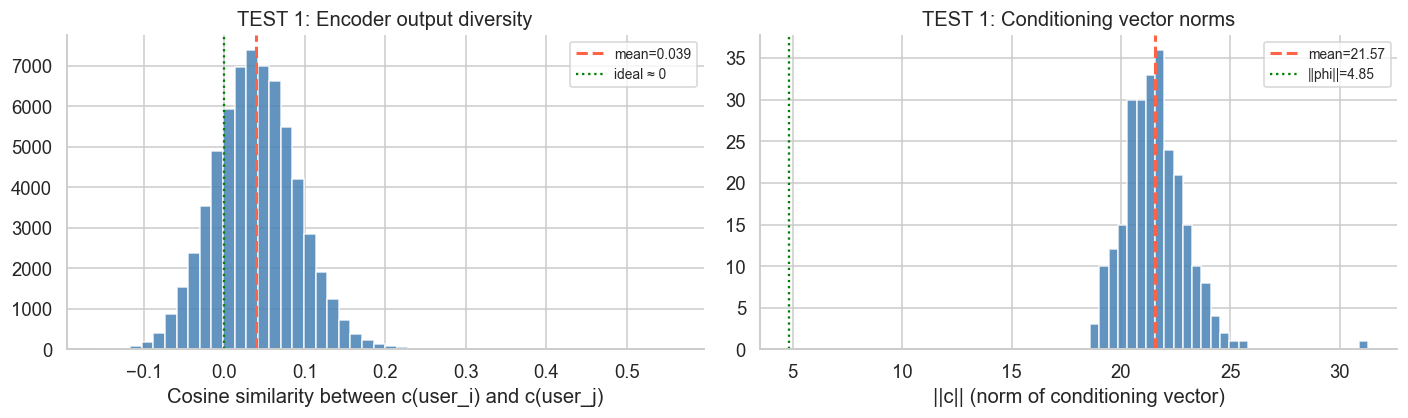

In [16]:
# ============================================================
# ТЕСТ 1: Разнообразие выходов encoder
# Если encoder выдаёт похожие c для разных пользователей
# → conditioning вырожден, модель не различает пользователей
# ============================================================

batch = next(iter(test_loader))
hist_batch = batch['history'].to(device)
mask_batch = batch['mask'].to(device)
N = len(hist_batch)

with torch.no_grad():
    c_batch = model.encoder(hist_batch, mask_batch)  # (N, 512)

c_n = torch.nn.functional.normalize(c_batch, dim=1).cpu().numpy()
sim_matrix = c_n @ c_n.T  # (N, N)
off_diag = sim_matrix[~np.eye(N, dtype=bool)]

print('=== TEST 1: Encoder output diversity ===')
print(f'Pairwise cosine(c_i, c_j) across {N} users:')
print(f'  mean = {off_diag.mean():.4f}  (0=diverse, 1=всё одинаково)')
print(f'  std  = {off_diag.std():.4f}')
print(f'  max  = {off_diag.max():.4f}')

# Также смотрим норму c — если она мала, conditioning слабый
c_norms = c_batch.norm(dim=1).cpu().numpy()
print(f'\n  ||c|| mean={c_norms.mean():.3f}, std={c_norms.std():.3f}')
print(f'  (для сравнения: ||phi|| = {model.phi.norm().item():.3f})')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.hist(off_diag, bins=50, color='steelblue', alpha=0.85, edgecolor='white')
ax.axvline(off_diag.mean(), color='tomato', ls='--', lw=2, label=f'mean={off_diag.mean():.3f}')
ax.axvline(0, color='green', ls=':', lw=1.5, label='ideal ≈ 0')
ax.set_xlabel('Cosine similarity between c(user_i) and c(user_j)')
ax.set_title('TEST 1: Encoder output diversity')
ax.legend(fontsize=9)

ax = axes[1]
ax.hist(c_norms, bins=30, color='steelblue', alpha=0.85, edgecolor='white')
ax.axvline(c_norms.mean(), color='tomato', ls='--', lw=2, label=f'mean={c_norms.mean():.2f}')
ax.axvline(model.phi.norm().item(), color='green', ls=':', lw=1.5,
           label=f'||phi||={model.phi.norm().item():.2f}')
ax.set_xlabel('||c|| (norm of conditioning vector)')
ax.set_title('TEST 1: Conditioning vector norms')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

=== TEST 2: History ablation (same z_0) ===
Cosine(oracle[real_hist], oracle[empty]):   mean=nan, std=nan
Cosine(oracle[real_hist], oracle[random]):  mean=0.2698, std=0.1917

Интерпретация:
  mean ≈ 1.0 → oracle не меняется при смене истории (модель игнорирует c)
  mean ≈ 0.0 → oracle сильно меняется (conditioning работает)


c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\matplotlib\axes\_axes.py:7104: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
c:\Users\ilyak\miniconda3\envs\torch_env\Lib\site-packages\matplotlib\axes\_axes.py:7105: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


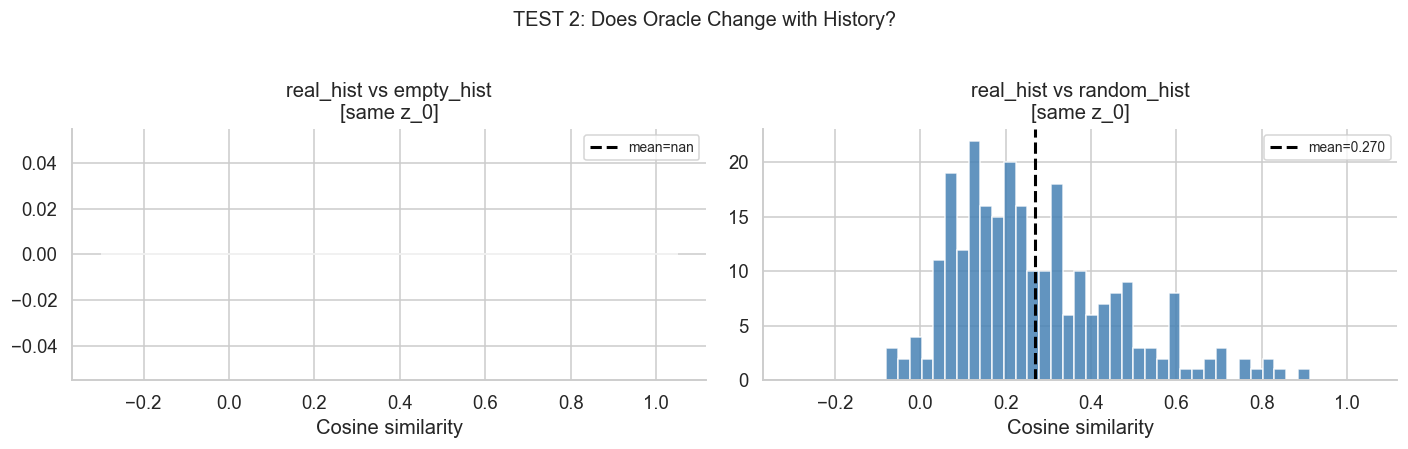

In [17]:
# ============================================================
# ТЕСТ 2: История vs пустая история (фиксированный z_0)
# Одинаковый seed → одинаковый стартовый шум для каждого пользователя
# Разница в oracle = чистый эффект conditioning
# ============================================================

hist_empty = torch.full_like(hist_batch, PADDING_IDX)
mask_empty = torch.zeros_like(mask_batch)
hist_rand  = torch.randint(0, model.n_items, hist_batch.shape, device=device)
mask_rand  = torch.ones_like(mask_batch)

SEED = 42
with torch.no_grad():
    torch.manual_seed(SEED); o_real  = model.sample(hist_batch, mask_batch, num_steps=NUM_STEPS, w_cfg=0.0)
    torch.manual_seed(SEED); o_empty = model.sample(hist_empty, mask_empty, num_steps=NUM_STEPS, w_cfg=0.0)
    torch.manual_seed(SEED); o_rand  = model.sample(hist_rand,  mask_rand,  num_steps=NUM_STEPS, w_cfg=0.0)

def cos_rows_t(a, b):
    a = torch.nn.functional.normalize(a, dim=1)
    b = torch.nn.functional.normalize(b, dim=1)
    return (a * b).sum(dim=1).cpu().numpy()

cos_re = cos_rows_t(o_real, o_empty)
cos_rr = cos_rows_t(o_real, o_rand)

print('=== TEST 2: History ablation (same z_0) ===')
print(f'Cosine(oracle[real_hist], oracle[empty]):   mean={cos_re.mean():.4f}, std={cos_re.std():.4f}')
print(f'Cosine(oracle[real_hist], oracle[random]):  mean={cos_rr.mean():.4f}, std={cos_rr.std():.4f}')
print()
print('Интерпретация:')
print('  mean ≈ 1.0 → oracle не меняется при смене истории (модель игнорирует c)')
print('  mean ≈ 0.0 → oracle сильно меняется (conditioning работает)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(-0.3, 1.05, 50)

ax = axes[0]
ax.hist(cos_re, bins=bins, color='tomato', alpha=0.85, edgecolor='white')
ax.axvline(cos_re.mean(), color='black', ls='--', lw=2, label=f'mean={cos_re.mean():.3f}')
ax.set_xlabel('Cosine similarity'); ax.set_title('real_hist vs empty_hist\n[same z_0]')
ax.legend(fontsize=9)

ax = axes[1]
ax.hist(cos_rr, bins=bins, color='steelblue', alpha=0.85, edgecolor='white')
ax.axvline(cos_rr.mean(), color='black', ls='--', lw=2, label=f'mean={cos_rr.mean():.3f}')
ax.set_xlabel('Cosine similarity'); ax.set_title('real_hist vs random_hist\n[same z_0]')
ax.legend(fontsize=9)

plt.suptitle('TEST 2: Does Oracle Change with History?', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

=== TEST 3: Denoiser sensitivity to c (same z_0) ===
Cosine(oracle[c_real], oracle[c_phi]):   mean=0.8802
Cosine(oracle[c_real], oracle[c_zero]):  mean=0.8680
Cosine(oracle[c_real], oracle[c_rand]):  mean=0.7983

Интерпретация:
  cos(c_real, c_phi) ≈ 1 → denoiser не отличает real от φ (FiLM мёртв)
  cos(c_real, c_rand) << cos(c_real, c_phi) → denoiser разборчив к направлению c


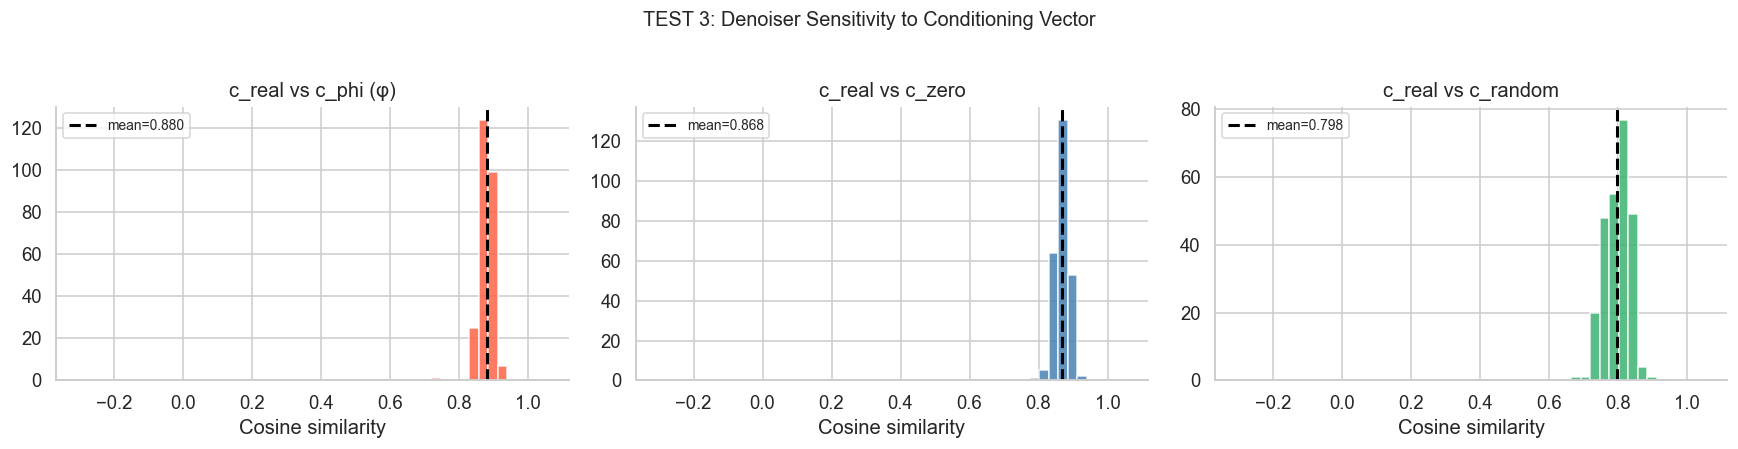


=== ИТОГОВАЯ ТАБЛИЦА ===
  T1 cosine(c_i, c_j):              0.0394  OK (diverse)
  T2 cosine(real_hist, empty):       nan  OK (sensitive)
  T3 cosine(c_real, c_phi):          0.8802  OK (uses c)
  T3 cosine(c_real, c_random):       0.7983


In [18]:
# ============================================================
# ТЕСТ 3: c_real vs c_phi vs c_zero (при одном z_0)
# Запускаем denoiser напрямую с разными c — чистая чувствительность к c
# ============================================================

def sample_with_c(model, c, num_steps=50, seed=42):
    B = c.shape[0]
    torch.manual_seed(seed)
    z = torch.randn(B, model.d_emb, device=device)
    dt = 1.0 / num_steps
    with torch.no_grad():
        for i in range(num_steps):
            tau = torch.full((B,), 1.0 - i * dt, device=device)
            z = z - dt * model.denoiser(z, tau, c)
    return z

with torch.no_grad():
    c_real_v = model.encoder(hist_batch, mask_batch)
    c_phi_v  = model.phi.unsqueeze(0).expand(N, -1)
    c_zero_v = torch.zeros_like(c_real_v)
    # Случайный c такой же нормы как реальный
    c_rand_v = torch.randn_like(c_real_v)
    c_rand_v = c_rand_v / c_rand_v.norm(dim=1, keepdim=True) * c_real_v.norm(dim=1, keepdim=True)

o_c_real = sample_with_c(model, c_real_v, num_steps=NUM_STEPS, seed=SEED)
o_c_phi  = sample_with_c(model, c_phi_v,  num_steps=NUM_STEPS, seed=SEED)
o_c_zero = sample_with_c(model, c_zero_v, num_steps=NUM_STEPS, seed=SEED)
o_c_rand = sample_with_c(model, c_rand_v, num_steps=NUM_STEPS, seed=SEED)

cos_rp = cos_rows_t(o_c_real, o_c_phi)
cos_rz = cos_rows_t(o_c_real, o_c_zero)
cos_rn = cos_rows_t(o_c_real, o_c_rand)

print('=== TEST 3: Denoiser sensitivity to c (same z_0) ===')
print(f'Cosine(oracle[c_real], oracle[c_phi]):   mean={cos_rp.mean():.4f}')
print(f'Cosine(oracle[c_real], oracle[c_zero]):  mean={cos_rz.mean():.4f}')
print(f'Cosine(oracle[c_real], oracle[c_rand]):  mean={cos_rn.mean():.4f}')
print()
print('Интерпретация:')
print('  cos(c_real, c_phi) ≈ 1 → denoiser не отличает real от φ (FiLM мёртв)')
print('  cos(c_real, c_rand) << cos(c_real, c_phi) → denoiser разборчив к направлению c')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.linspace(-0.3, 1.05, 50)
for ax, vals, title, color in zip(
    axes,
    [cos_rp, cos_rz, cos_rn],
    ['c_real vs c_phi (φ)', 'c_real vs c_zero', 'c_real vs c_random'],
    ['tomato', 'steelblue', 'mediumseagreen']
):
    ax.hist(vals, bins=bins, color=color, alpha=0.85, edgecolor='white')
    ax.axvline(vals.mean(), color='black', ls='--', lw=2, label=f'mean={vals.mean():.3f}')
    ax.set_xlabel('Cosine similarity')
    ax.set_title(title)
    ax.legend(fontsize=9)

plt.suptitle('TEST 3: Denoiser Sensitivity to Conditioning Vector', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print('\n=== ИТОГОВАЯ ТАБЛИЦА ===')
print(f'  T1 cosine(c_i, c_j):              {off_diag.mean():.4f}  '
      f'{"OK (diverse)" if off_diag.mean() < 0.5 else "COLLAPSED"}')
print(f'  T2 cosine(real_hist, empty):       {cos_re.mean():.4f}  '
      f'{"IGNORES HIST" if cos_re.mean() > 0.9 else "OK (sensitive)"}')
print(f'  T3 cosine(c_real, c_phi):          {cos_rp.mean():.4f}  '
      f'{"IGNORES c" if cos_rp.mean() > 0.9 else "OK (uses c)"}')
print(f'  T3 cosine(c_real, c_random):       {cos_rn.mean():.4f}')

## 8. Траектория ODE: расстояние до таргета по шагам расшумления

Запускаем Euler ODE и на каждом шаге замеряем:
- **Косинусное расстояние** (1 - cosine similarity) между текущим `z_t` и таргетом
- **MAE** между `z_t` и таргетом

Усредняем по нескольким пользователям из теста.

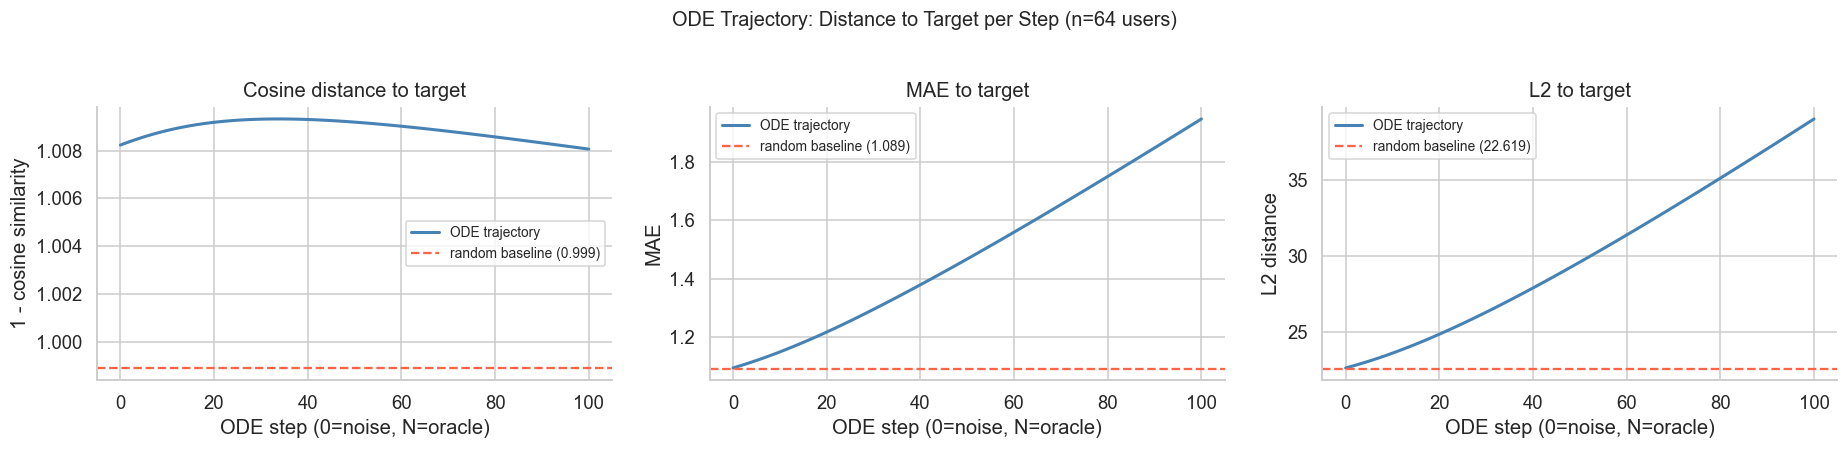

Step   0 (noise):  cos_dist=1.0082  MAE=1.0934  L2=22.6626
Step 100 (oracle): cos_dist=1.0081  MAE=1.9477  L2=39.0439
Random baseline:   cos_dist=0.9989  MAE=1.0889  L2=22.6190
Best cosine step:  100  (cos_dist=1.0081)


In [19]:
N_TRAJ  = 64
N_STEPS = NUM_STEPS

batch = next(iter(test_loader))
hist_traj   = batch['history'][:N_TRAJ].to(device)
mask_traj   = batch['mask'][:N_TRAJ].to(device)
target_traj = batch['target'][:N_TRAJ].to(device)

with torch.no_grad():
    target_emb_traj = model.encoder.item_embedding(target_traj)
    c_traj = model.encoder(hist_traj, mask_traj)

def step_metrics(z, target):
    z_n = torch.nn.functional.normalize(z, dim=1)
    t_n = torch.nn.functional.normalize(target, dim=1)
    cos_dist = (1 - (z_n * t_n).sum(dim=1)).mean().item()
    mae      = (z - target).abs().mean().item()
    l2       = (z - target).norm(dim=1).mean().item()
    return cos_dist, mae, l2

cos_dist_steps, mae_steps, l2_steps = [], [], []

torch.manual_seed(SEED)
z = torch.randn(N_TRAJ, model.d_emb, device=device)

cd, mae, l2 = step_metrics(z, target_emb_traj)
cos_dist_steps.append(cd); mae_steps.append(mae); l2_steps.append(l2)

dt = 1.0 / N_STEPS
with torch.no_grad():
    for i in range(N_STEPS):
        tau = torch.full((N_TRAJ,), 1.0 - i * dt, device=device)
        z = z - dt * model.denoiser(z, tau, c_traj)
        cd, mae, l2 = step_metrics(z, target_emb_traj)
        cos_dist_steps.append(cd); mae_steps.append(mae); l2_steps.append(l2)

steps = np.arange(N_STEPS + 1)

# Random baseline
with torch.no_grad():
    z_rand = torch.randn(N_TRAJ, model.d_emb, device=device)
    cd_rand, mae_rand, l2_rand = step_metrics(z_rand, target_emb_traj)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, vals, baseline, ylabel, title in zip(
    axes,
    [cos_dist_steps, mae_steps, l2_steps],
    [cd_rand, mae_rand, l2_rand],
    ['1 - cosine similarity', 'MAE', 'L2 distance'],
    ['Cosine distance to target', 'MAE to target', 'L2 to target'],
):
    ax.plot(steps, vals, lw=2, color='steelblue', label='ODE trajectory')
    ax.axhline(baseline, color='tomato', ls='--', lw=1.5,
               label=f'random baseline ({baseline:.3f})')
    ax.set_xlabel('ODE step (0=noise, N=oracle)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=9)

plt.suptitle(f'ODE Trajectory: Distance to Target per Step (n={N_TRAJ} users)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f'Step   0 (noise):  cos_dist={cos_dist_steps[0]:.4f}  MAE={mae_steps[0]:.4f}  L2={l2_steps[0]:.4f}')
print(f'Step {N_STEPS:>3} (oracle): cos_dist={cos_dist_steps[-1]:.4f}  MAE={mae_steps[-1]:.4f}  L2={l2_steps[-1]:.4f}')
print(f'Random baseline:   cos_dist={cd_rand:.4f}  MAE={mae_rand:.4f}  L2={l2_rand:.4f}')
best = int(np.argmin(cos_dist_steps))
print(f'Best cosine step:  {best}  (cos_dist={cos_dist_steps[best]:.4f})')

## 9. Encoder relevance: содержит ли c информацию о таргете?

Проверяем главный вопрос: **кодирует ли encoder что-то полезное для рекомендации?**

- Если `cosine(project(c_real), target) > cosine(project(c_rand), target)` → encoder несёт сигнал о таргете
- Если разница ≈ 0 → encoder разнообразен, но не полезен для FM

=== Encoder Relevance Test ===

cosine(random_proj(c_real), target):  -0.0014 ± 0.0618
cosine(truncate(c_real),    target):  0.0007 ± 0.0633
cosine(random_vector,       target):  0.0012 ± 0.0627  ← baseline (нет истории)

Интерпретация:
  Если cosine(c_real) >> cosine(random) → encoder несёт сигнал о таргете
  Если cosine(c_real) ≈  cosine(random) → encoder не кодирует таргет-релевантное


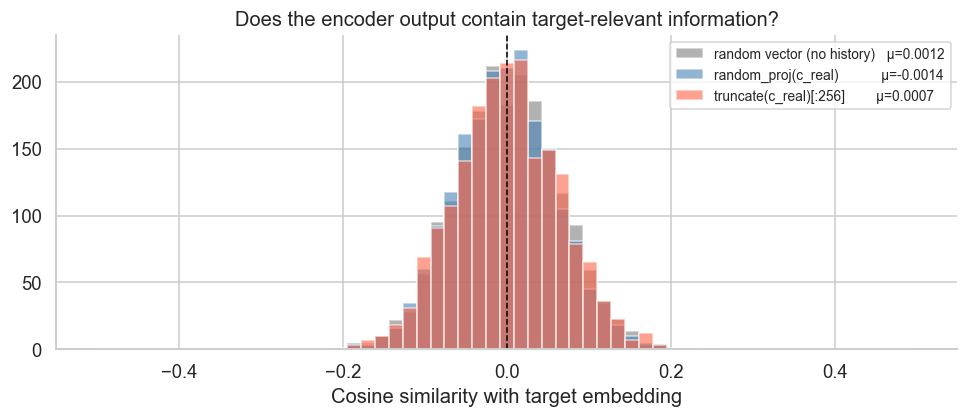

In [20]:
# Собираем c и target_emb для всего тестового сета
c_all_list, target_all_list = [], []

with torch.no_grad():
    for batch in test_loader:
        history = batch['history'].to(device)
        mask    = batch['mask'].to(device)
        target  = batch['target'].to(device)

        c         = model.encoder(history, mask)                    # (B, 512)
        tgt_emb   = model.encoder.item_embedding(target)            # (B, 256)

        c_all_list.append(c.cpu())
        target_all_list.append(tgt_emb.cpu())

c_all      = torch.cat(c_all_list)       # (N_test, 512)
target_all = torch.cat(target_all_list)  # (N_test, 256)

# ------------------------------------------------------------------ #
# Проекция c (512d) → 256d несколькими способами
# ------------------------------------------------------------------ #

# 1. Случайная проекция (baseline — нет информации о таргете)
torch.manual_seed(0)
W_rand = torch.randn(512, 256) / 256**0.5
c_proj_rand = (c_all @ W_rand)                         # (N_test, 256)

# 2. Используем первые 256 компонент c (тривиальная проекция)
c_proj_trunc = c_all[:, :256]                           # (N_test, 256)

# 3. Случайный вектор той же нормы как c (контроль — нет истории вообще)
c_random_baseline = torch.randn_like(c_all[:, :256])
c_random_baseline = (c_random_baseline
                     / c_random_baseline.norm(dim=1, keepdim=True)
                     * c_all.norm(dim=1, keepdim=True).mean())

# ------------------------------------------------------------------ #
# Cosine similarity между проекцией c и target embedding
# ------------------------------------------------------------------ #

def batch_cosine(a, b):
    """Косинусное сходство построчно: (N, D), (N, D) → (N,)"""
    a_n = torch.nn.functional.normalize(a.float(), dim=1)
    b_n = torch.nn.functional.normalize(b.float(), dim=1)
    return (a_n * b_n).sum(dim=1).numpy()

cos_rand_proj   = batch_cosine(c_proj_rand,        target_all)
cos_trunc_proj  = batch_cosine(c_proj_trunc,       target_all)
cos_no_history  = batch_cosine(c_random_baseline,  target_all)

print('=== Encoder Relevance Test ===')
print()
print(f'cosine(random_proj(c_real), target):  {cos_rand_proj.mean():.4f} ± {cos_rand_proj.std():.4f}')
print(f'cosine(truncate(c_real),    target):  {cos_trunc_proj.mean():.4f} ± {cos_trunc_proj.std():.4f}')
print(f'cosine(random_vector,       target):  {cos_no_history.mean():.4f} ± {cos_no_history.std():.4f}  ← baseline (нет истории)')
print()
print('Интерпретация:')
print('  Если cosine(c_real) >> cosine(random) → encoder несёт сигнал о таргете')
print('  Если cosine(c_real) ≈  cosine(random) → encoder не кодирует таргет-релевантное')

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(-0.5, 0.5, 60)
ax.hist(cos_no_history,  bins=bins, alpha=0.6, color='gray',        edgecolor='white',
        label=f'random vector (no history)   μ={cos_no_history.mean():.4f}')
ax.hist(cos_rand_proj,   bins=bins, alpha=0.6, color='steelblue',   edgecolor='white',
        label=f'random_proj(c_real)           μ={cos_rand_proj.mean():.4f}')
ax.hist(cos_trunc_proj,  bins=bins, alpha=0.6, color='tomato',      edgecolor='white',
        label=f'truncate(c_real)[:256]        μ={cos_trunc_proj.mean():.4f}')
ax.axvline(0, color='black', ls='--', lw=1)
ax.set_xlabel('Cosine similarity with target embedding')
ax.set_title('Does the encoder output contain target-relevant information?')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 10. Простые baseline: последний товар и среднее истории vs таргет

Проверяем: насколько последний товар в истории и среднее эмбеддингов истории близки к таргету.  
Эти числа — нижняя планка для encoder: если `c` хуже них, encoder деградировал.

=== Baselines vs Encoder ===

cosine(last item,       target): 0.0145 ± 0.1268
cosine(mean history,    target): 0.0097 ± 0.1182
cosine(random_proj(c),  target): -0.0014 ± 0.0618
cosine(truncate(c),     target): 0.0007 ± 0.0633
cosine(random vector,   target): 0.0012 ± 0.0627

Интерпретация:
  last item / mean_hist — тривиальные baseline (без обучения)
  Если encoder хуже них — он деградировал (хуже простого эвристика)


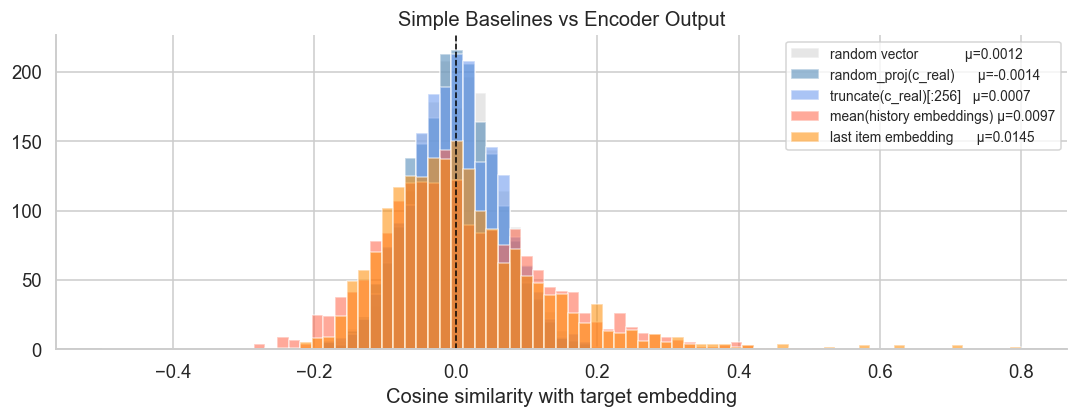

In [21]:
# Собираем: последний товар, среднее истории, таргет — для всего тест-сета
last_item_list, mean_hist_list, target_list2 = [], [], []

with torch.no_grad():
    for batch in test_loader:
        history = batch['history'].to(device)  # (B, L), padding слева
        mask    = batch['mask'].to(device)      # (B, L), 1=реальный, 0=padding
        target  = batch['target'].to(device)

        # Эмбеддинги всей истории: (B, L, 256)
        hist_emb = model.encoder.item_embedding(history)

        # Последний товар — всегда последняя позиция (padding слева)
        last_emb = hist_emb[:, -1, :]           # (B, 256)

        # Среднее по реальным позициям (исключаем padding)
        mask_e = mask.unsqueeze(-1)              # (B, L, 1)
        mean_emb = (hist_emb * mask_e).sum(dim=1) / mask_e.sum(dim=1).clamp(min=1)  # (B, 256)

        # Таргет
        tgt_emb = model.encoder.item_embedding(target)  # (B, 256)

        last_item_list.append(last_emb.cpu())
        mean_hist_list.append(mean_emb.cpu())
        target_list2.append(tgt_emb.cpu())

last_item_emb = torch.cat(last_item_list)   # (N_test, 256)
mean_hist_emb = torch.cat(mean_hist_list)   # (N_test, 256)
target_emb2   = torch.cat(target_list2)     # (N_test, 256)

# Косинусные сходства
cos_last   = batch_cosine(last_item_emb, target_emb2)
cos_mean   = batch_cosine(mean_hist_emb, target_emb2)

# Для сравнения — снова c_real (уже посчитан выше)
# random_proj и truncate из ячейки 9
cos_c_rand_proj = batch_cosine(c_proj_rand, target_all)
cos_c_trunc     = batch_cosine(c_proj_trunc, target_all)

print('=== Baselines vs Encoder ===')
print()
print(f'cosine(last item,       target): {cos_last.mean():.4f} ± {cos_last.std():.4f}')
print(f'cosine(mean history,    target): {cos_mean.mean():.4f} ± {cos_mean.std():.4f}')
print(f'cosine(random_proj(c),  target): {cos_c_rand_proj.mean():.4f} ± {cos_c_rand_proj.std():.4f}')
print(f'cosine(truncate(c),     target): {cos_c_trunc.mean():.4f} ± {cos_c_trunc.std():.4f}')
print(f'cosine(random vector,   target): {cos_no_history.mean():.4f} ± {cos_no_history.std():.4f}')
print()
print('Интерпретация:')
print('  last item / mean_hist — тривиальные baseline (без обучения)')
print('  Если encoder хуже них — он деградировал (хуже простого эвристика)')

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(-0.5, 0.8, 80)
for vals, label, color in [
    (cos_no_history,   f'random vector            μ={cos_no_history.mean():.4f}',   'lightgray'),
    (cos_c_rand_proj,  f'random_proj(c_real)      μ={cos_c_rand_proj.mean():.4f}',  'steelblue'),
    (cos_c_trunc,      f'truncate(c_real)[:256]   μ={cos_c_trunc.mean():.4f}',      'cornflowerblue'),
    (cos_mean,         f'mean(history embeddings) μ={cos_mean.mean():.4f}',          'tomato'),
    (cos_last,         f'last item embedding      μ={cos_last.mean():.4f}',          'darkorange'),
]:
    ax.hist(vals, bins=bins, alpha=0.55, edgecolor='white', label=label, color=color)

ax.axvline(0, color='black', ls='--', lw=1)
ax.set_xlabel('Cosine similarity with target embedding')
ax.set_title('Simple Baselines vs Encoder Output')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()